<a href="https://colab.research.google.com/github/paulLieber98/mental-health-ml-research/blob/main/final_dataset_mental_health.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#google drive mount, dependencies, and df initialization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import SMOTE

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.ensemble import GradientBoostingClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from sklearn.model_selection import GridSearchCV

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [ ]:
from google.colab import drive
drive.mount('/content/drive') #dataset from : #https://www.kaggle.com/datasets/souvikahmed071/social-media-and-mental-health/data
df = pd.read_csv("/content/drive/My Drive/smmh dataset mental health/smmh.csv")

Mounted at /content/drive


In [ ]:

# to have all data shown. just run this.
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [ ]:
df

,Timestamp,1. What is your age?,2. Gender,3. Relationship Status,4. Occupation Status,5. What type of organizations are you affiliated with?,6. Do you use social media?,7. What social media platforms do you commonly use?,8. What is the average time you spend on social media every day?,9. How often do you find yourself using Social media without a specific purpose?,10. How often do you get distracted by Social media when you are busy doing something?,11. Do you feel restless if you haven't used Social media in a while?,"12. On a scale of 1 to 5, how easily distracted are you?","13. On a scale of 1 to 5, how much are you bothered by worries?",14. Do you find it difficult to concentrate on things?,"15. On a scale of 1-5, how often do you compare yourself to other successful people through the use of social media?","16. Following the previous question, how do you feel about these comparisons, generally speaking?",17. How often do you look to seek validation from features of social media?,18. How often do you feel depressed or down?,"19. On a scale of 1 to 5, how frequently does your interest in daily activities fluctuate?","20. On a scale of 1 to 5, how often do you face issues regarding sleep?"
0,4/18/2022 19:18:47,21.0,Male,In a relationship,University Student,University,Yes,"Facebook, Twitter, Instagram, YouTube, Discord...",Between 2 and 3 hours,5,3,2,5,2,5,2,3,2,5,4,5
1,4/18/2022 19:19:28,21.0,Female,Single,University Student,University,Yes,"Facebook, Twitter, Instagram, YouTube, Discord...",More than 5 hours,4,3,2,4,5,4,5,1,1,5,4,5
2,4/18/2022 19:25:59,21.0,Female,Single,University Student,University,Yes,"Facebook, Instagram, YouTube, Pinterest",Between 3 and 4 hours,3,2,1,2,5,4,3,3,1,4,2,5
3,4/18/2022 19:29:43,21.0,Female,Single,University Student,University,Yes,"Facebook, Instagram",More than 5 hours,4,2,1,3,5,3,5,1,2,4,3,2
4,4/18/2022 19:33:31,21.0,Female,Single,University Student,University,Yes,"Facebook, Instagram, YouTube",Between 2 and 3 hours,3,5,4,4,5,5,3,3,3,4,4,1
5,4/18/2022 19:33:48,22.0,Female,Single,University Student,University,Yes,"Facebook, Twitter, Instagram, YouTube, Discord...",Between 2 and 3 hours,4,4,2,3,4,3,4,4,3,3,2,4
6,4/18/2022 19:36:12,21.0,Female,Married,University Student,University,Yes,"Facebook, Instagram, YouTube, Snapchat, TikTok",Between 3 and 4 hours,4,3,2,2,4,3,5,3,4,5,5,3
7,4/18/2022 19:36:17,21.0,Female,In a relationship,University Student,University,Yes,"Facebook, Instagram, YouTube",More than 5 hours,5,2,3,3,3,1,1,3,1,5,5,1
8,4/18/2022 19:39:36,21.0,Female,In a relationship,University Student,University,Yes,"Facebook, Instagram, YouTube",More than 5 hours,5,2,3,3,1,1,1,3,1,5,5,1
9,4/18/2022 19:41:34,20.0,Male,Single,University Student,University,No,"Reddit, Pinterest",Less than an Hour,1,1,1,1,1,1,1,1,1,1,1,1


In [ ]:
#@title graphing and plotting

In [ ]:
df.columns = df.columns.str.strip() # removing white space

In [ ]:
#rename columns

df.rename(columns={'1. What is your age?': 'Age',
                   '2. Gender': 'Gender',
                   '3. Relationship Status': 'Relationship Status',
                   '4. Occupation Status': 'Occupation',
                   '5. What type of organizations are you affiliated with?': 'Affiliations',
                   '6. Do you use social media?': 'Use social media ?',
                   '7. What social media platforms do you commonly use?': 'Social media platforms used',
                   '8. What is the average time you spend on social media every day?': 'Daily social media use',
                   '9. How often do you find yourself using Social media without a specific purpose?': 'Social media use w/o purpose',
                   '10. How often do you get distracted by Social media when you are busy doing something?': 'Social media distraction frequency',
                   '11. Do you feel restless if you haven\'t used Social media in a while?': "Restless",
                   '12. On a scale of 1 to 5, how easily distracted are you?': 'Distracted',
                   '13. On a scale of 1 to 5, how much are you bothered by worries?': 'Worried',
                   '14. Do you find it difficult to concentrate on things?': 'Difficult to concentrate',
                   '15. On a scale of 1-5, how often do you compare yourself to other successful people through the use of social media?': 'Social media people comparisons',
                   '16. Following the previous question, how do you feel about these comparisons, generally speaking?': 'Feel about social media people comparisons',
                   '17. How often do you look to seek validation from features of social media?': 'Social media validation',
                   '18. How often do you feel depressed or down?': 'Depression frequency',
                   '19. On a scale of 1 to 5, how frequently does your interest in daily activities fluctuate?': 'Daily activities interest',
                   '20. On a scale of 1 to 5, how often do you face issues regarding sleep?': 'Sleep issues frequency'
                   }, inplace=True)


In [ ]:
df = df.dropna() #removes NA value rows

In [ ]:
#dropping columns - RUN
df = df.drop(columns = ['Timestamp', 'Use social media ?'])

In [ ]:
#turning depression frequency column into binary
df['Depression frequency'] = df['Depression frequency'].replace({1: 0, 2: 0, 3: 1, 4: 1, 5: 1}) # 0 = Not Depressed, 1 = Depressed

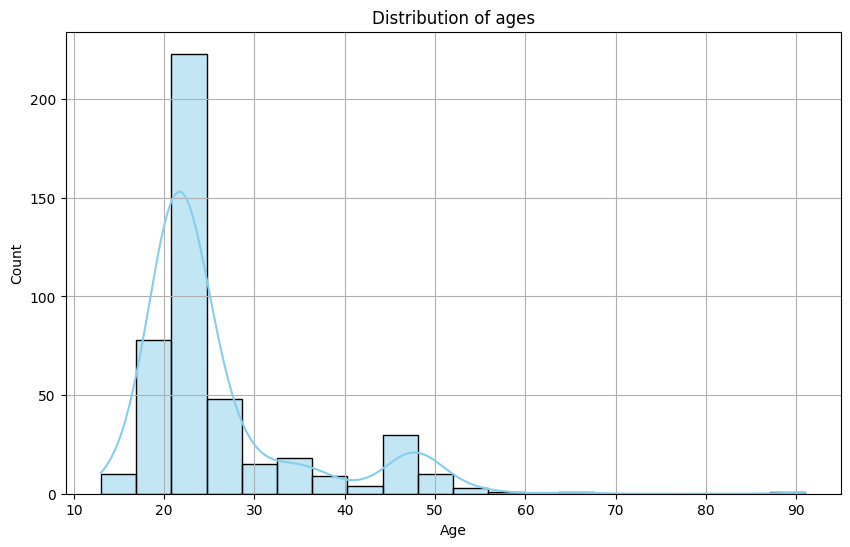

In [ ]:
plt.figure(figsize = (10, 6))
sns.histplot(df['Age'], bins = 20, kde = True, color = 'skyblue', edgecolor = 'black')
plt.title('Distribution of ages')
plt.xlabel('Age')
plt.ylabel('Count')
plt.grid(True)
plt.show()

In [ ]:
#RUN THIS
df = df[df['Gender'].isin(['Male', 'Female'])] #dropping all genders but Male and Female

In [ ]:
#RUN THIS
# grouping ages
bins = [0, 18, 25, 35, 45, 55, 100]
labels = ['>18', '18-25', '26-35', '36-45', '46-55', '56+']
df['Age group'] = pd.cut(df['Age'], bins = bins, labels = labels, right = False)

#dropping original Age column
df = df.drop(columns = ['Age'])

In [ ]:
#RUN THIS
#defining 6 affiliation values with anything with multiple values in the 'multiple affiliations value'
#fill na's and standardize the capital spelling
df['Affiliations'] = df['Affiliations'].fillna('None')
df['Affiliations'] = df['Affiliations'].str.strip().str.title()
df['Affiliations'] = df['Affiliations'].str.replace('Goverment', 'Government')
df['Affiliations'] = df['Affiliations'].str.replace('N/A', 'None')

#defining the single allowed categories
single_categories = ['University', 'School', 'Private', 'Company', 'Government']

#making function to map each row
def simplify_affiliation(value):
    #if theres a comma, then it's a combination --> multiple affiliations
    if ',' in value:
        return 'Multiple Affiliations'
    #otherwise keep if in allowed list
    elif value in single_categories:
        return value
    #anything else like None can be grouped into multiple
    else:
        return 'Multiple Affiliations'

#calling/applying function
df['Affiliations'] = df['Affiliations'].apply(simplify_affiliation)

In [ ]:
#RUN THIS
#cleanup "social media used" column

#ORIGINAL CHATGPT CODE NOT TOUCHED/EDITED

# # Step 1: Define your grouped platforms
# main_platforms = ['Facebook', 'Instagram', 'YouTube', 'Snapchat']
# other_platforms = ['Reddit', 'Discord', 'Twitter', 'TikTok', 'Pinterest']

# # Step 2: Make one column per main platform
# for platform in main_platforms:
#     df[f'Uses {platform}'] = df['Social media platforms used'].str.contains(platform, case=False)

# # Step 3: One column for "other" platforms — True if any are found
# df['Uses Other'] = df['Social media platforms used'].apply(
#     lambda x: any(other in x for other in other_platforms)
# )

# # Step 4: Drop the original column now that it's cleaned
# df.drop('Social media platforms used', axis=1, inplace=True)



#RECODED

#group platforms
main_platforms = ['Facebook', 'Instagram', 'YouTube', 'Snapchat']
other_platforms = ['Reddit', 'Discord', 'Twitter', 'TikTok', 'Pinterest']


#title for column
for platform in main_platforms:
    df[f'Uses {platform}'] = df['Social media platforms used'].str.contains(platform, case=False)

# "other platform used" column
df['Uses Other'] = df['Social media platforms used'].apply(
    lambda x: any(other in x for other in other_platforms)
)


#drop the original messy column
df.drop('Social media platforms used', axis=1, inplace=True)

In [ ]:
# encode categorial columns
df = pd.get_dummies(df, columns = ['Age group',
                                   'Gender',
                                   'Relationship Status',
                                   'Occupation',
                                   'Affiliations',
                                   'Daily social media use'], drop_first = True)

In [ ]:
df.head()

,Social media use w/o purpose,Social media distraction frequency,Restless,Distracted,Worried,Difficult to concentrate,Social media people comparisons,Feel about social media people comparisons,Social media validation,Depression frequency,Daily activities interest,Sleep issues frequency,Uses Facebook,Uses Instagram,Uses YouTube,Uses Snapchat,Uses Other,Age group_18-25,Age group_26-35,Age group_36-45,Age group_46-55,Age group_56+,Gender_Male,Relationship Status_In a relationship,Relationship Status_Married,Relationship Status_Single,Occupation_Salaried Worker,Occupation_School Student,Occupation_University Student,Affiliations_Government,Affiliations_Multiple Affiliations,Affiliations_Private,Affiliations_School,Affiliations_University,Daily social media use_Between 2 and 3 hours,Daily social media use_Between 3 and 4 hours,Daily social media use_Between 4 and 5 hours,Daily social media use_Less than an Hour,Daily social media use_More than 5 hours
0,5,3,2,5,2,5,2,3,2,1,4,1,True,True,True,False,True,True,False,False,False,False,True,True,False,False,False,False,True,False,False,False,False,True,True,False,False,False,False
1,4,3,2,4,5,4,5,1,1,1,4,1,True,True,True,False,True,True,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,True,False,False,False,False,True
2,3,2,1,2,5,4,3,3,1,1,2,1,True,True,True,False,True,True,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,True,False,True,False,False,False
3,4,2,1,3,5,3,5,1,2,1,3,0,True,True,False,False,False,True,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,True,False,False,False,False,True
4,3,5,4,4,5,5,3,3,3,1,4,0,True,True,True,False,False,True,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,True,True,False,False,False,False


<ipython-input-17-9aabeb5fc37c>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x = 'Depression frequency', data = df, palette = 'coolwarm')


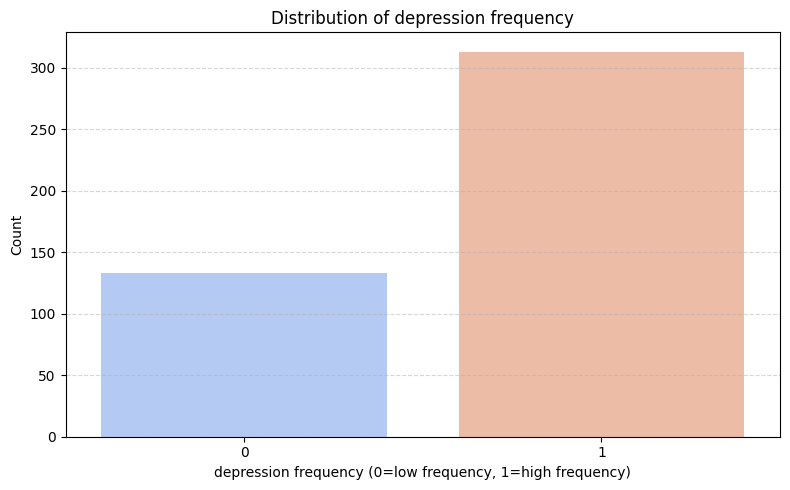

In [ ]:
#making more visuals
plt.figure(figsize = (8, 5))
sns.countplot(x = 'Depression frequency', data = df, palette = 'coolwarm')
plt.title('Distribution of depression frequency')
plt.xlabel('depression frequency (0=low frequency, 1=high frequency)')
plt.ylabel('Count')
plt.xticks(ticks = range(0, 2), labels = [0, 1])
plt.grid(axis = 'y', linestyle = '--', alpha = 0.5)
plt.tight_layout()
plt.show()

In [ ]:
#making more visuals
plt.figure(figsize = (8, 5))
sns.countplot(x = 'Depression frequency', data = df, palette = 'coolwarm')
plt.title('Distribution of depression frequency')
plt.xlabel('depression frequency (0=low frequency, 1=high frequency)')
plt.ylabel('Count')
plt.xticks(ticks = range(0, 2), labels = [0, 1])
plt.grid(axis = 'y', linestyle = '--', alpha = 0.5)
plt.tight_layout()
plt.show()

In [ ]:
#RUN THIS

#turning sleep issues frequency column into binary - RUN THIS!!!!
df['Sleep issues frequency'] = df['Sleep issues frequency'].apply(lambda x: 1 if x >= 4 else 0)

In [ ]:
df['Sleep issues frequency'].value_counts()

,count
Sleep issues frequency,
0,229
1,217


In [ ]:
df['Depression frequency'].value_counts()

,count
Depression frequency,
1,313
0,133


<ipython-input-20-e9edef7d7f30>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x = 'Sleep issues frequency', data = df, palette = 'coolwarm')


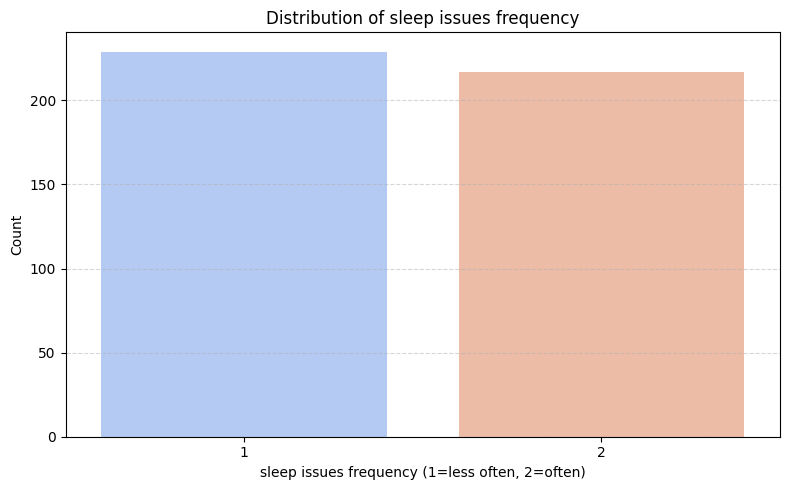

In [ ]:
#distribution of sleep issues frequency visualization
plt.figure(figsize = (8, 5))
sns.countplot(x = 'Sleep issues frequency', data = df, palette = 'coolwarm')
plt.title('Distribution of sleep issues frequency')
plt.xlabel('sleep issues frequency (1=less often, 2=often)')
plt.ylabel('Count')
plt.xticks(ticks = [0, 1], labels = ['1', '2'])
plt.grid(axis = 'y', linestyle = '--', alpha = 0.5)
plt.tight_layout()
plt.show()

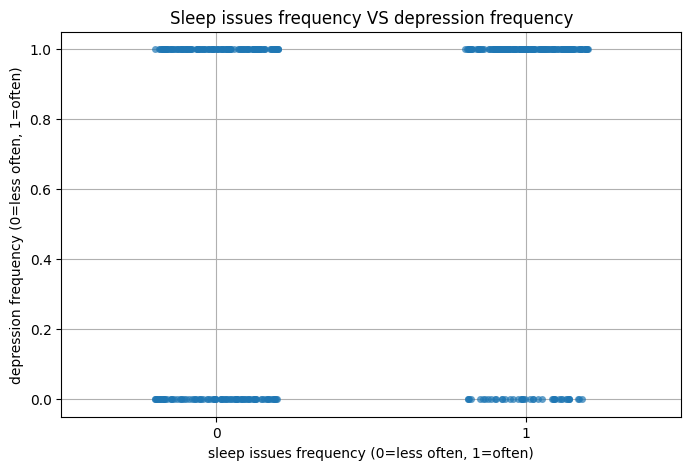

In [ ]:
#visualization for Sleep issues frequency VS depression frequency
plt.figure(figsize = (8, 5))
sns.stripplot(x = 'Sleep issues frequency', y = 'Depression frequency', data = df, jitter = 0.2, alpha = 0.7)
plt.title('Sleep issues frequency VS depression frequency')
plt.xlabel('sleep issues frequency (0=less often, 1=often)')
plt.ylabel('depression frequency (0=less often, 1=often)')
plt.grid(True)
plt.show()

In [ ]:
#visualization for Sleep issues frequency VS depression frequency - table
pd.crosstab(df['Sleep issues frequency'], df['Depression frequency'])

Depression frequency,0,1
Sleep issues frequency,,
0,90,139
1,43,174


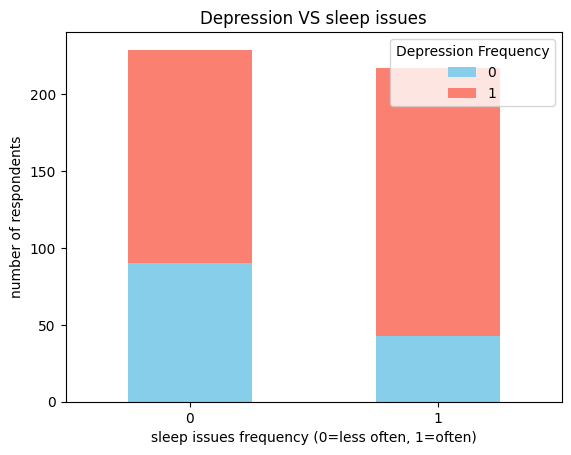

In [ ]:
#visualization for Sleep issues frequency VS depression frequency
cross_tab = pd.crosstab(df['Sleep issues frequency'], df['Depression frequency'])
cross_tab.plot(kind = 'bar', stacked = True, color = ['skyblue', 'salmon'])
plt.title('Depression VS sleep issues')
plt.xlabel('sleep issues frequency (0=less often, 1=often)')
plt.ylabel('number of respondents')
plt.legend(title = 'Depression Frequency')
plt.xticks(rotation = 0)
plt.show()

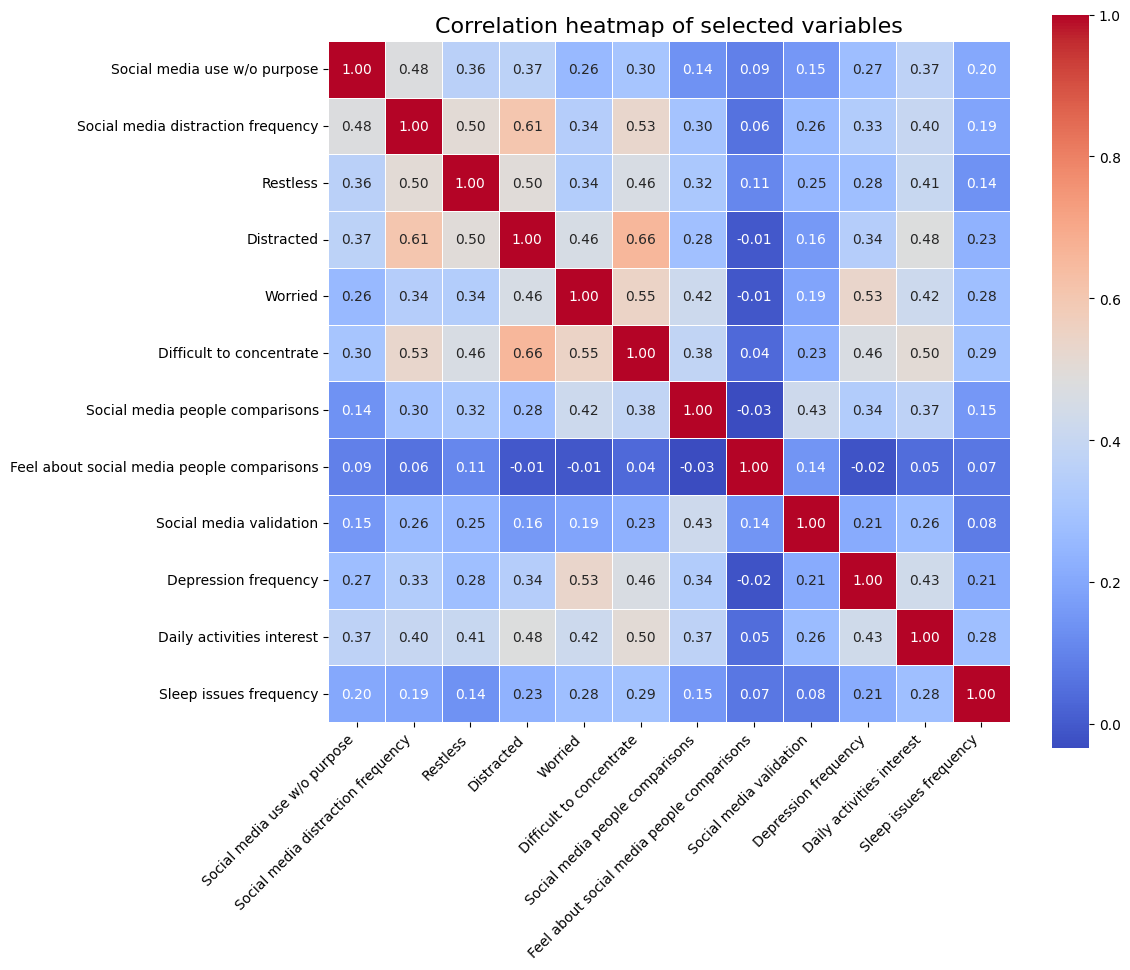

In [ ]:
selected_columns = ['Social media use w/o purpose', 'Social media distraction frequency',
       'Restless', 'Distracted', 'Worried', 'Difficult to concentrate',
       'Social media people comparisons',
       'Feel about social media people comparisons', 'Social media validation',
       'Depression frequency', 'Daily activities interest',
       'Sleep issues frequency']

correlation_selected = df[selected_columns].corr()
plt.figure(figsize = (12, 10))
sns.heatmap(correlation_selected, cmap = 'coolwarm', annot = True, fmt = '.2f', linewidths = 0.5, square = True, cbar = {'shrink': '0.5'})
plt.title('Correlation heatmap of selected variables', fontsize = 16)
plt.xticks(rotation = 45, ha = 'right')
plt.tight_layout()
plt.show()

In [ ]:
#split the data
X = df.drop(columns = ['Depression frequency'])
y = df['Depression frequency']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, test_size = 0.2, stratify = y)

In [ ]:
#augment the 0 values to the 1 values (134 to 317) using SMOTE (library used in first cell)
smote = SMOTE(random_state = 42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

In [ ]:
#y_train_resampled.value_counts()
y_train.value_counts()

,count
Depression frequency,
1,250
0,106


In [ ]:
df['Depression frequency'].value_counts()

,count
Depression frequency,
1,313
0,133


In [ ]:
pd.Series(y_train_resampled).value_counts()

,count
Depression frequency,
1,250
0,250


In [ ]:
#@title use logistic regression
#split data was already done + train_test_split function

#model initialization
model = LogisticRegression(max_iter = 1000)

#fit/training the model
model.fit(X_train_resampled, y_train_resampled)

#prediction
y_pred = model.predict(X_test)

#eval
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7444444444444445
Confusion Matrix:
 [[12 15]
 [ 8 55]]
Classification Report:
               precision    recall  f1-score   support

           0       0.60      0.44      0.51        27
           1       0.79      0.87      0.83        63

    accuracy                           0.74        90
   macro avg       0.69      0.66      0.67        90
weighted avg       0.73      0.74      0.73        90



In [ ]:
# precision:

# 1. answering the question of all the people that the model predicts as having high depression frequency, how many actually do ? in other words, for your 1 class(high depression),
# the correct answer is 1 and the model is correct 80% of the time.

# 2. high precision is important if false positives are costly, meaning that wrongly flagging someone as 'depressed'. this will lead to unnecessarily treatment and
# interventions



#recall:

# 1. the question that recall answers: of all the number of ppl that actually have high frequency, how many did the model accurately identify ? results show 0.89 meaning that
# the model accurately identify 89% of the people that have high depression frequency. very different from 80% from above.

# 2. high recall is important if missing someone with depression (false negatives) is more harmful. better to over-flag/predict innacurately than the other way around.

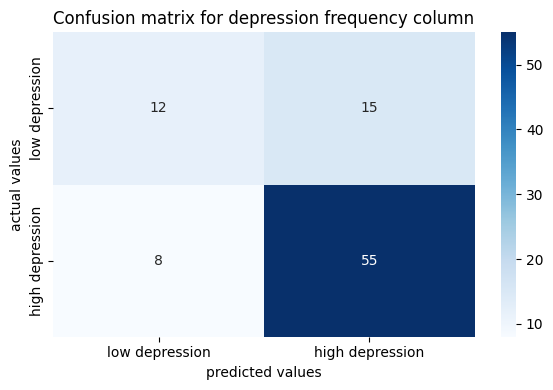

In [ ]:
cm = confusion_matrix(y_test, y_pred)
labels = ['low depression', 'high depression']
plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', xticklabels = labels, yticklabels = labels)
plt.xlabel('predicted values')
plt.ylabel('actual values')
plt.title('Confusion matrix for depression frequency column')
plt.tight_layout()
plt.show()

In [ ]:
#@title what eval results mean

# key takeaway:

# --> the model more accurately predicts high depression vs low depression

# Class 0 = Not Depressed
# Metric	Meaning
# Precision 0.64	When model says "not depressed", it's right 64% of the time
# Recall 0.57	Out of all not depressed people, it found 57% of them
# F1 Score 0.60	Mix of precision and recall – okay performance

# Class 1 = Depressed
# Metric	Meaning
# Precision 0.82	When it says "depressed", it's right 82% of the time
# Recall 0.85	Out of all depressed people, it correctly found 85%
# F1 Score 0.83	Strong balance – very good at identifying depression

In [ ]:
#new model: Decision Trees

#init model
tree_model = DecisionTreeClassifier(random_state = 42, max_depth = 5)

#train model
tree_model.fit(X_train_resampled, y_train_resampled)

#testing model
y_pred = tree_model.predict(X_test)

#eval
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.6888888888888889
Confusion Matrix:
 [[15 12]
 [16 47]]
Classification Report:
               precision    recall  f1-score   support

           0       0.48      0.56      0.52        27
           1       0.80      0.75      0.77        63

    accuracy                           0.69        90
   macro avg       0.64      0.65      0.64        90
weighted avg       0.70      0.69      0.69        90



In [ ]:
#new model: Random Forest

#init model
rf_model = RandomForestClassifier(random_state = 42, n_estimators = 100, max_depth = 5)

#train model
rf_model.fit(X_train_resampled, y_train_resampled)

#testing model
y_pred = rf_model.predict(X_test)

#eval
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7555555555555555
Confusion Matrix:
 [[15 12]
 [10 53]]
Classification Report:
               precision    recall  f1-score   support

           0       0.60      0.56      0.58        27
           1       0.82      0.84      0.83        63

    accuracy                           0.76        90
   macro avg       0.71      0.70      0.70        90
weighted avg       0.75      0.76      0.75        90



In [ ]:
#new model: Gradient Boosting

#init model
grad_boost_model = GradientBoostingClassifier(random_state = 42)

#train model
grad_boost_model.fit(X_train_resampled, y_train_resampled)

#predictions
y_pred = grad_boost_model.predict(X_test)

#eval
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.6777777777777778
Confusion Matrix:
 [[11 16]
 [13 50]]
Classification Report:
               precision    recall  f1-score   support

           0       0.46      0.41      0.43        27
           1       0.76      0.79      0.78        63

    accuracy                           0.68        90
   macro avg       0.61      0.60      0.60        90
weighted avg       0.67      0.68      0.67        90



In [ ]:
#new model: K-Nearest Neighbors (KNN)

#init
knn_model = KNeighborsClassifier(n_neighbors=5)

#train
knn_model.fit(X_train_resampled, y_train_resampled)

#predict
y_pred = knn_model.predict(X_test)

#eval
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7666666666666667
Confusion Matrix:
 [[20  7]
 [14 49]]
Classification Report:
               precision    recall  f1-score   support

           0       0.59      0.74      0.66        27
           1       0.88      0.78      0.82        63

    accuracy                           0.77        90
   macro avg       0.73      0.76      0.74        90
weighted avg       0.79      0.77      0.77        90



best performing model BEFORE FINE-TUNING: KNN

```
best performing model BEFORE FINE-TUNING: KNN
worst performing model BEFORE FINE-TUNING: Gradient Boosting

```




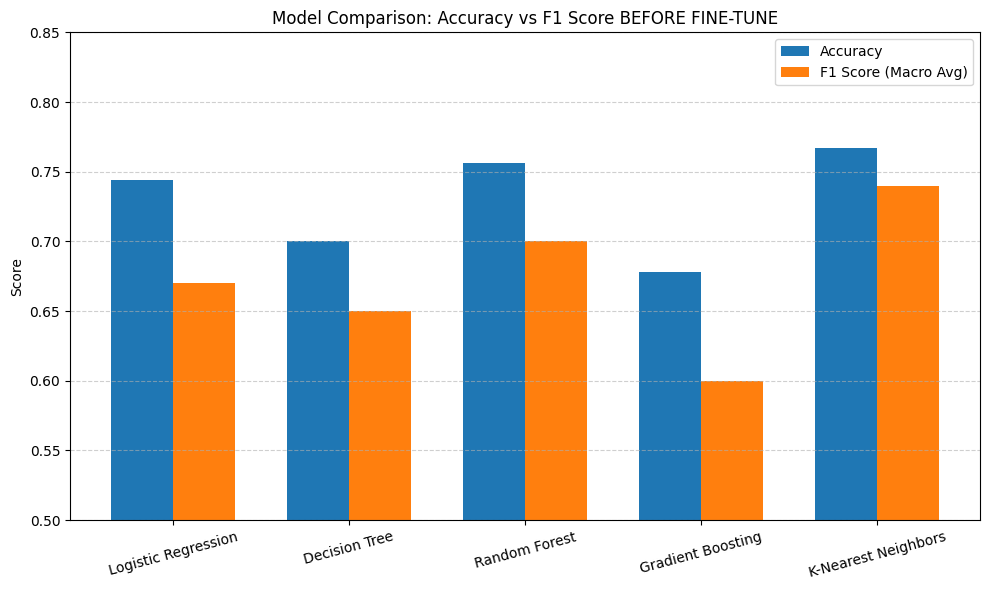

In [ ]:
#@title visualization BEFORE FINE-TUNING for each model metric scores

# Model names
models = [
    'Logistic Regression',
    'Decision Tree',
    'Random Forest',
    'Gradient Boosting',
    'K-Nearest Neighbors'
]

# Accuracy scores from your outputs
accuracies = [0.744, 0.70, 0.756, 0.678, 0.767]

# Macro-averaged F1-scores from your outputs
f1_scores = [0.67, 0.65, 0.70, 0.60, 0.74]

# Plotting
x = range(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar([i - width/2 for i in x], accuracies, width, label='Accuracy')
ax.bar([i + width/2 for i in x], f1_scores, width, label='F1 Score (Macro Avg)')

# Labels and formatting
ax.set_ylabel('Score')
ax.set_title('Model Comparison: Accuracy vs F1 Score BEFORE FINE-TUNE')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.set_ylim([0.5, 0.85])
ax.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
#@title fine-tuning

#starting off w/ KNN model bc of its highest accuracy so far GOING IN ORDER OF BEST TO WORST FROM THE VISUAL ABOVE

# Define the parameter grid
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],       # Try odd values
    'weights': ['uniform', 'distance'],   # 'distance' can improve performance sometimes
    'p': [1, 2]  # 1 = Manhattan, 2 = Euclidean
}

# Initialize the base model
knn = KNeighborsClassifier()

# Set up GridSearchCV
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='f1_macro', n_jobs=-1)

# Fit on the resampled training set
grid_search.fit(X_train_resampled, y_train_resampled)

# Best parameters
print("Best Parameters:", grid_search.best_params_)

# Use the best model to predict on test set
best_knn = grid_search.best_estimator_
y_pred = best_knn.predict(X_test)

#eval
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Best Parameters: {'n_neighbors': 9, 'p': 1, 'weights': 'distance'}
Accuracy: 0.7666666666666667
Confusion Matrix:
 [[21  6]
 [15 48]]
Classification Report:
               precision    recall  f1-score   support

           0       0.58      0.78      0.67        27
           1       0.89      0.76      0.82        63

    accuracy                           0.77        90
   macro avg       0.74      0.77      0.74        90
weighted avg       0.80      0.77      0.77        90



In [ ]:
#next fine-tuning model: Random Forest

# Define the parameter grid
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 10, None],
    'max_features': ['sqrt', 'log2'],
    'criterion': ['gini', 'entropy']
}

# Initialize the base model
rf = RandomForestClassifier(random_state=42)

# Set up GridSearchCV
grid_search = GridSearchCV(rf, param_grid, cv=5, scoring='f1_macro', n_jobs=-1)

# Fit on the resampled training set
grid_search.fit(X_train_resampled, y_train_resampled)

# Show best parameters
print("Best Parameters:", grid_search.best_params_)

# Use best model for predictions
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)

#eval
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Best Parameters: {'criterion': 'entropy', 'max_depth': None, 'max_features': 'log2', 'n_estimators': 100}
Accuracy: 0.7666666666666667
Confusion Matrix:
 [[16 11]
 [10 53]]
Classification Report:
               precision    recall  f1-score   support

           0       0.62      0.59      0.60        27
           1       0.83      0.84      0.83        63

    accuracy                           0.77        90
   macro avg       0.72      0.72      0.72        90
weighted avg       0.76      0.77      0.77        90



In [ ]:
#next fine tuning model: Logistic Regression

# Define parameter grid
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],          # Regularization strength (lower = more regularization)
    'penalty': ['l1', 'l2'],               # Type of regularization
    'solver': ['liblinear', 'saga']        # Solvers that support l1/l2
}

# Initialize model
log_reg = LogisticRegression(max_iter=1000)

# Grid search
grid_search = GridSearchCV(log_reg, param_grid, cv=5, scoring='f1_macro', n_jobs=-1)
grid_search.fit(X_train_resampled, y_train_resampled)

# Best model
print("Best Parameters:", grid_search.best_params_)

# Predict
best_log_reg = grid_search.best_estimator_
y_pred = best_log_reg.predict(X_test)

#eval
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Best Parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'saga'}
Accuracy: 0.7666666666666667
Confusion Matrix:
 [[15 12]
 [ 9 54]]
Classification Report:
               precision    recall  f1-score   support

           0       0.62      0.56      0.59        27
           1       0.82      0.86      0.84        63

    accuracy                           0.77        90
   macro avg       0.72      0.71      0.71        90
weighted avg       0.76      0.77      0.76        90



In [ ]:
#next fine tune model: Decision Tree:

# Define the parameter grid
param_grid = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}

# Initialize model
tree = DecisionTreeClassifier(random_state=42)

# Grid search
grid_search = GridSearchCV(tree, param_grid, cv=5, scoring='f1_macro', n_jobs=-1)
grid_search.fit(X_train_resampled, y_train_resampled)

# Best model
print("Best Parameters:", grid_search.best_params_)

# Predict
best_tree = grid_search.best_estimator_
y_pred = best_tree.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Best Parameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 2}
Accuracy: 0.6555555555555556
Confusion Matrix:
 [[14 13]
 [18 45]]
Classification Report:
               precision    recall  f1-score   support

           0       0.44      0.52      0.47        27
           1       0.78      0.71      0.74        63

    accuracy                           0.66        90
   macro avg       0.61      0.62      0.61        90
weighted avg       0.67      0.66      0.66        90



In [ ]:
#next fine tune model: Gradient Boosting:# Define parameter grid
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

# Initialize model
gb = GradientBoostingClassifier(random_state=42)

# Grid search
grid_search = GridSearchCV(gb, param_grid, cv=5, scoring='f1_macro', n_jobs=-1)
grid_search.fit(X_train_resampled, y_train_resampled)

# Best model
print("Best Parameters:", grid_search.best_params_)

# Predict
best_gb = grid_search.best_estimator_
y_pred = best_gb.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Best Parameters: {'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 50}
Accuracy: 0.7555555555555555
Confusion Matrix:
 [[15 12]
 [10 53]]
Classification Report:
               precision    recall  f1-score   support

           0       0.60      0.56      0.58        27
           1       0.82      0.84      0.83        63

    accuracy                           0.76        90
   macro avg       0.71      0.70      0.70        90
weighted avg       0.75      0.76      0.75        90



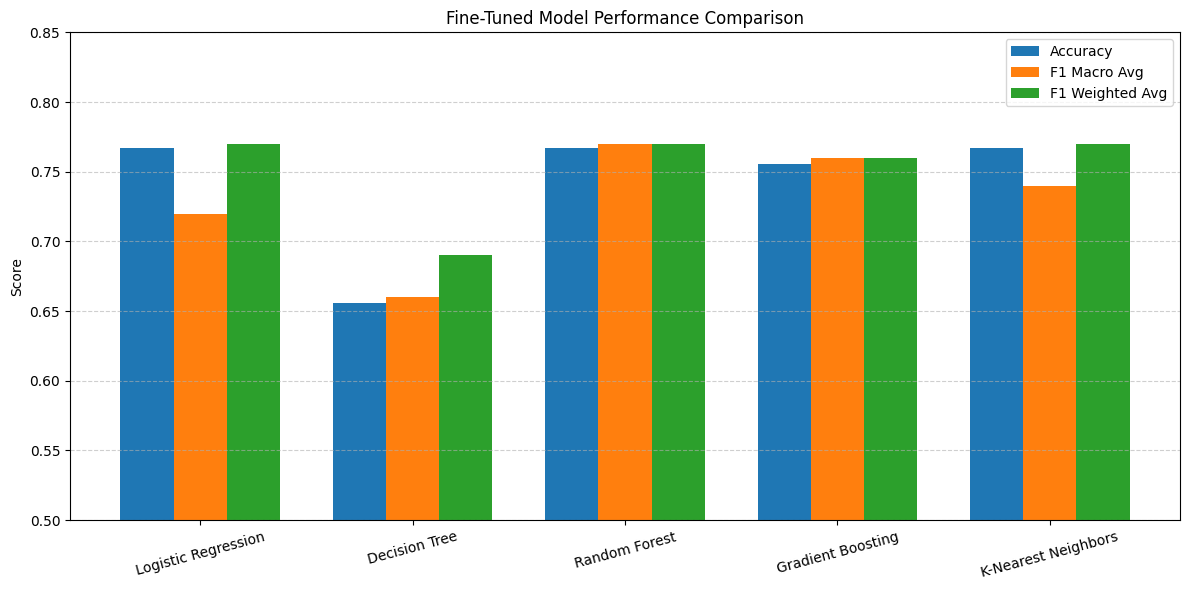

In [ ]:
#@title visual for FINE TUNED models

# Model names
models = [
    'Logistic Regression',
    'Decision Tree',
    'Random Forest',
    'Gradient Boosting',
    'K-Nearest Neighbors'
]

# Performance metrics
accuracies = [0.7667, 0.6556, 0.7667, 0.7556, 0.7667]
f1_macro =  [0.72,   0.66,   0.77,   0.76,   0.74]
f1_weighted = [0.77, 0.69,   0.77,   0.76,   0.77]

# Bar plot
x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - width, accuracies, width, label='Accuracy')
bars2 = ax.bar(x, f1_macro, width, label='F1 Macro Avg')
bars3 = ax.bar(x + width, f1_weighted, width, label='F1 Weighted Avg')

# Labels and formatting
ax.set_ylabel('Score')
ax.set_title('Fine-Tuned Model Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.set_ylim([0.5, 0.85])
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.6)

# Show plot
plt.tight_layout()
plt.show()

In [ ]:
#@title trying out NEURAL NETWORKS

# Scale features (very important for neural networks)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_resampled)
X_test_scaled = scaler.transform(X_test)

# Build model
model = Sequential()
model.add(Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)))
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='sigmoid'))  # Binary classification

# Compile
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Train
history = model.fit(X_train_scaled, y_train_resampled, epochs=30, batch_size=16, validation_split=0.2, verbose=1)

# Evaluate
loss, accuracy = model.evaluate(X_test_scaled, y_test)
print("Test Accuracy:", accuracy)

y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype("int32")

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6545 - loss: 0.6373 - val_accuracy: 0.7000 - val_loss: 0.6157
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7905 - loss: 0.4621 - val_accuracy: 0.8400 - val_loss: 0.4516
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7794 - loss: 0.4236 - val_accuracy: 0.8700 - val_loss: 0.3904
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8403 - loss: 0.3442 - val_accuracy: 0.8800 - val_loss: 0.3344
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8123 - loss: 0.3679 - val_accuracy: 0.8700 - val_loss: 0.3264
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8322 - loss: 0.3239 - val_accuracy: 0.9200 - val_loss: 0.2871
Epoch 7/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8505 - loss: 0.3231 - val_accuracy: 0.9100 - val_loss: 0.2673
Epoch 8/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8940 - loss: 0.2762 - val_accuracy: 0.9200 - val_loss

In [ ]:
#fine tuned nn

# 1. Scale your features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_resampled)
X_test_scaled = scaler.transform(X_test)

# 2. Build the model
model = Sequential()
model.add(Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],)))
model.add(Dropout(0.3))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(1, activation='sigmoid'))  # Binary output

# 3. Compile the model
optimizer = Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# 4. Early stopping to prevent overfitting
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# 5. Train the model
history = model.fit(
    X_train_scaled, y_train_resampled,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# 6. Evaluate
loss, accuracy = model.evaluate(X_test_scaled, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# 7. Convert predictions to class labels
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype("int32")

# 8. Print metrics
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.5578 - loss: 0.7022 - val_accuracy: 0.6200 - val_loss: 0.6695
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7409 - loss: 0.5565 - val_accuracy: 0.8000 - val_loss: 0.5016
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7772 - loss: 0.4767 - val_accuracy: 0.8100 - val_loss: 0.4674
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8319 - loss: 0.4035 - val_accuracy: 0.8200 - val_loss: 0.4132
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8283 - loss: 0.4219 - val_accuracy: 0.8300 - val_loss: 0.3656
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8202 - loss: 0.4009 - val_accuracy: 0.8300 - val_loss: 0.3393
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7898 - loss: 0.4394 - val_accuracy: 0.8300 - val_loss: 0.3374
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8304 - loss: 0.3873 - val_accuracy: 0.8800 - val_loss: 0.

In [ ]:
#trying out CNNs

# 1. Scale your features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_resampled)
X_test_scaled = scaler.transform(X_test)

# 2. Reshape for Conv1D: (samples, time steps, features)
X_train_cnn = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_test_cnn = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

# 3. Build the CNN model
model = Sequential()
model.add(Conv1D(filters=32, kernel_size=3, activation='relu', input_shape=(X_train_cnn.shape[1], 1)))
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.3))
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(1, activation='sigmoid'))  # Binary classification

# 4. Compile
optimizer = Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# 5. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# 6. Train
history = model.fit(
    X_train_cnn, y_train_resampled,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# 7. Evaluate
loss, accuracy = model.evaluate(X_test_cnn, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# 8. Predict & evaluate
y_pred_prob = model.predict(X_test_cnn)
y_pred = (y_pred_prob > 0.5).astype("int32")

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6890 - loss: 0.5987 - val_accuracy: 0.6100 - val_loss: 0.6700
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8202 - loss: 0.4720 - val_accuracy: 0.8600 - val_loss: 0.3885
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8214 - loss: 0.4111 - val_accuracy: 0.7800 - val_loss: 0.4411
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8196 - loss: 0.4472 - val_accuracy: 0.8500 - val_loss: 0.3765
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8283 - loss: 0.3796 - val_accuracy: 0.8700 - val_loss: 0.3016
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8047 - loss: 0.4253 - val_accuracy: 0.8600 - val_loss: 0.3428
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8358 - loss: 0.3760 - val_accuracy: 0.9100 - val_loss: 0.2589
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8139 - loss: 0.3939 - val_accuracy: 0.8800 - val_loss: 0.

Test Loss: 0.4867611825466156
Test Accuracy: 0.7444444298744202
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Confusion Matrix:
 [[13 14]
 [ 9 54]]
Classification Report:
               precision    recall  f1-score   support

           0       0.59      0.48      0.53        27
           1       0.79      0.86      0.82        63

    accuracy                           0.74        90
   macro avg       0.69      0.67      0.68        90
weighted avg       0.73      0.74      0.74        90



In [ ]:
#fine tuning CNN

# 1. Reshape input (already scaled before)
X_train_cnn = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_test_cnn = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

# 2. Build upgraded CNN model
model = Sequential()
model.add(Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(X_train_cnn.shape[1], 1)))
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.25))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.25))
model.add(Dense(1, activation='sigmoid'))

# 3. Compile
optimizer = Adam(learning_rate=0.0003)
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# 4. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

# 5. Train
history = model.fit(
    X_train_cnn, y_train_resampled,
    epochs=100,
    batch_size=8,  # smaller batch = more updates
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# 6. Evaluate
loss, accuracy = model.evaluate(X_test_cnn, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# 7. Predict
y_pred_prob = model.predict(X_test_cnn)
y_pred = (y_pred_prob > 0.5).astype("int32")

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.6719 - loss: 0.5934 - val_accuracy: 0.8000 - val_loss: 0.5151
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7877 - loss: 0.4570 - val_accuracy: 0.8600 - val_loss: 0.3374
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8325 - loss: 0.3891 - val_accuracy: 0.9000 - val_loss: 0.2988
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8301 - loss: 0.3925 - val_accuracy: 0.9300 - val_loss: 0.2498
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8505 - loss: 0.3524 - val_accuracy: 0.9300 - val_loss: 0.2512
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8382 - loss: 0.3736 - val_accuracy: 0.9100 - val_loss: 0.3282
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7973 - loss: 0.3837 - val_accuracy: 0.9300 - val_loss: 0.2618
Epoch 8/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8473 - loss: 0.3396 - val_accuracy: 0.9300 -

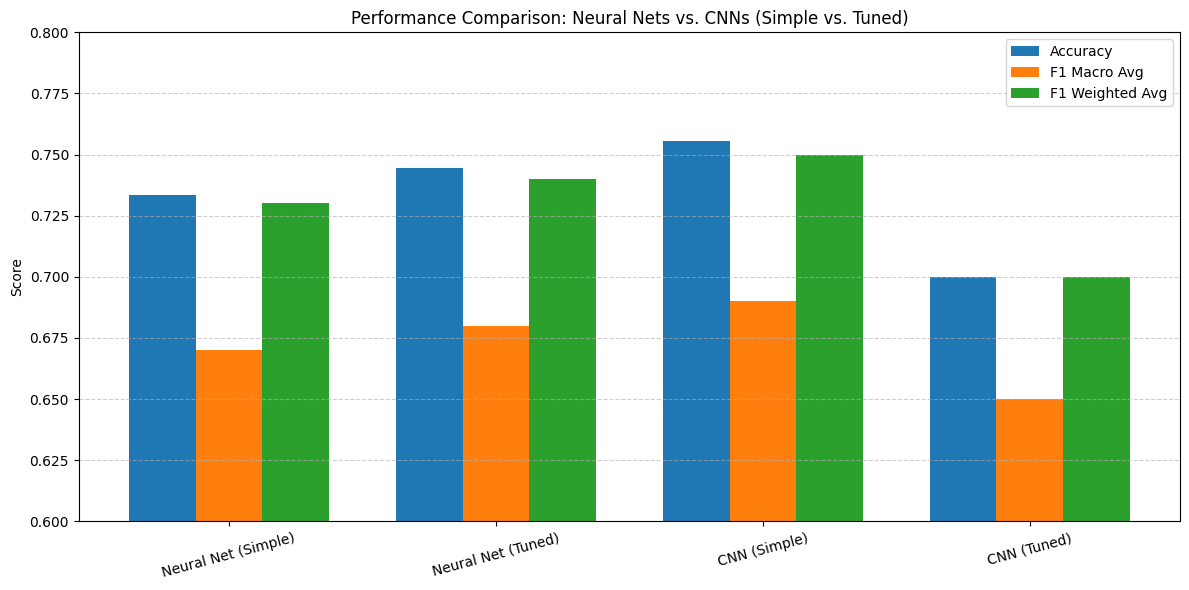

In [ ]:
#visual for NN vs fine-tuned NN vs CNN vs fine-tuned CNN

# Model labels
models = [
    'Neural Net (Simple)',
    'Neural Net (Tuned)',
    'CNN (Simple)',
    'CNN (Tuned)'
]

# Scores
accuracies = [0.7333, 0.7444, 0.7556, 0.7000]
f1_macro = [0.67, 0.68, 0.69, 0.65]
f1_weighted = [0.73, 0.74, 0.75, 0.70]

# Bar chart settings
x = np.arange(len(models))
width = 0.25

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width, accuracies, width, label='Accuracy')
ax.bar(x, f1_macro, width, label='F1 Macro Avg')
ax.bar(x + width, f1_weighted, width, label='F1 Weighted Avg')

# Styling
ax.set_ylabel('Score')
ax.set_title('Performance Comparison: Neural Nets vs. CNNs (Simple vs. Tuned)')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.set_ylim([0.6, 0.8])
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

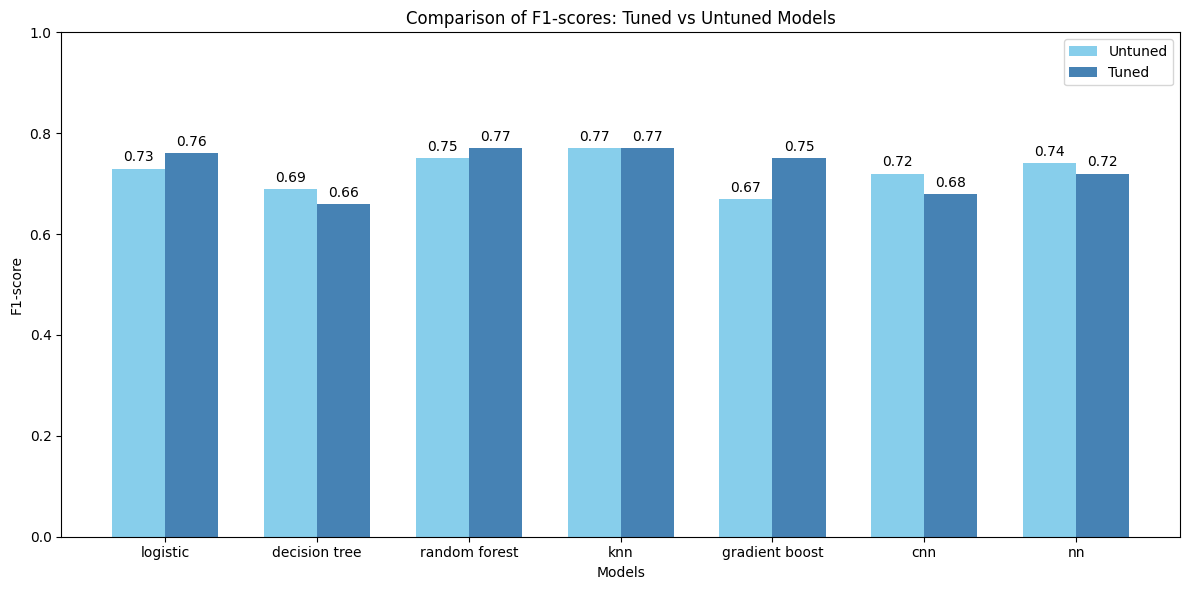

In [ ]:
#creating bar plot of all models that are tuned + UNtuned
models = ['logistic', 'decision tree', 'random forest', 'knn', 'gradient boost', 'cnn', 'nn']
f1_untuned = [0.73, 0.69, 0.75, 0.77, 0.67, 0.72, 0.74] #put in all numbers
f1_tuned = [0.76, 0.66, 0.77, 0.77, 0.75, 0.68, 0.72] #same here

x_label = np.arange(len(models))
width = 0.35
fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x_label - width/2, f1_untuned, width, label='Untuned', color='skyblue')
bars2 = ax.bar(x_label + width/2, f1_tuned, width, label='Tuned', color='steelblue')

# Add labels, title, and legend
ax.set_ylabel('F1-score')
ax.set_xlabel('Models')
ax.set_title('Comparison of F1-scores: Tuned vs Untuned Models')
ax.set_xticks(x_label)
ax.set_xticklabels(models)
ax.set_ylim(0, 1)
ax.legend()

# Annotate the bars with exact values
for bar in bars1 + bars2:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # vertical offset
                textcoords="offset points",
                ha='center', va='bottom')

plt.tight_layout()
plt.show()

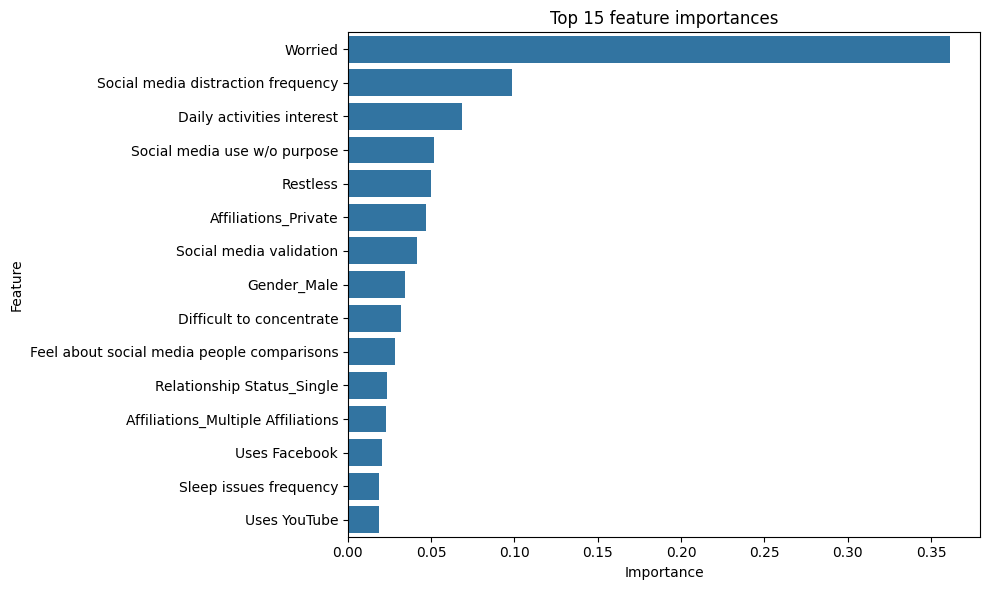

In [ ]:
#DECISION TREE
#getting feature importance from the trained model
importances = best_tree.feature_importances_
feature_names = X_train_resampled.columns

#creating dataframe
feature_dt = pd.DataFrame({
              'Feature': feature_names,
              'Importance': importances
}).sort_values(by = 'Importance', ascending = False)

#plotting
plt.figure(figsize = (10, 6))
sns.barplot(x = 'Importance', y = 'Feature', data = feature_dt.head(15))
plt.title('Top 15 feature importances')
plt.tight_layout()
plt.show()

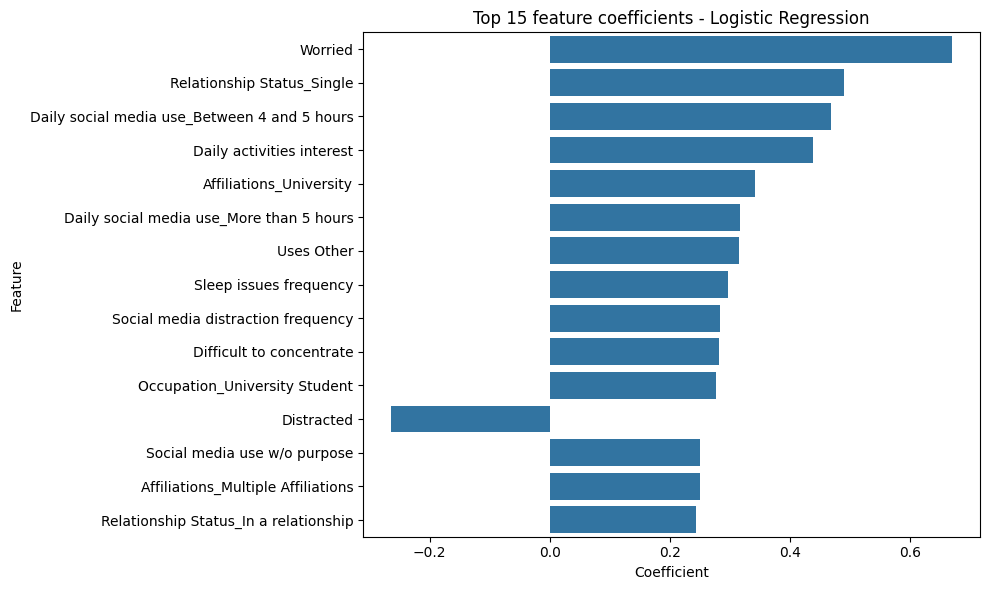

In [ ]:
#LOGISTIC REGRESSION
#getting feature coefficients from the trained model
coefficients = best_log_reg.coef_[0]
feature_names = X_train_resampled.columns

#creating dataframe
coef_lr = pd.DataFrame({
              'Feature': feature_names,
              'Coefficient': coefficients
}).sort_values(by = 'Coefficient', key = abs, ascending = False)

#plotting
plt.figure(figsize = (10, 6))
sns.barplot(x = 'Coefficient', y = 'Feature', data = coef_lr.head(15))
plt.title('Top 15 feature coefficients - Logistic Regression')
plt.tight_layout()
plt.show()

In [ ]:
#barplot results:

# if Distracted is highly correlated with any other feature, then the true value of the feature importance is being assigned to that other correlated value.

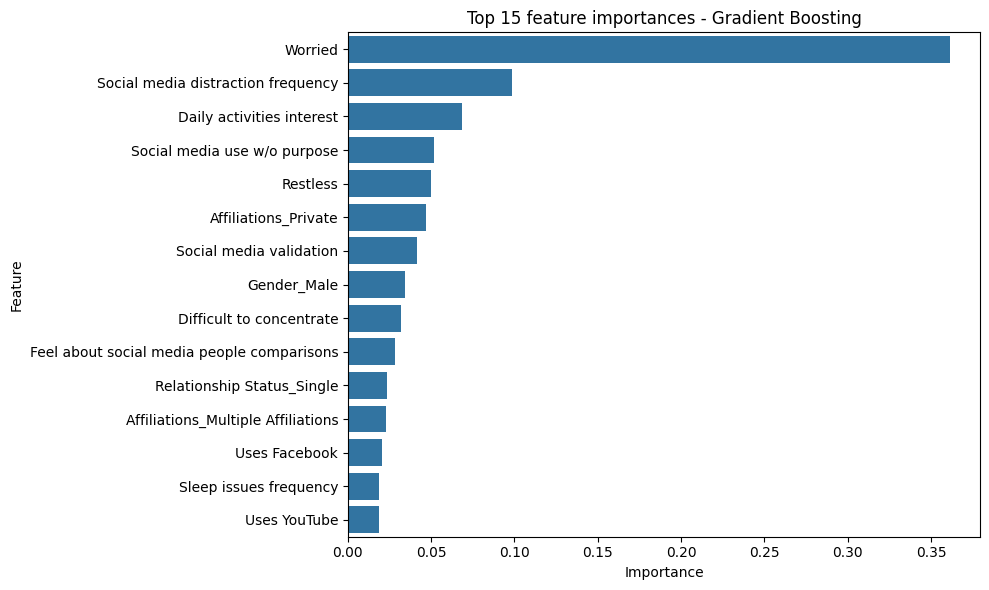

In [ ]:
#GRADIENT BOOSTING
#getting feature importances from the trained model
importances2 = best_gb.feature_importances_
feature_names = X_train_resampled.columns

#creating dataframe
feat_imp_df = pd.DataFrame({
              'Feature': feature_names,
              'Importance': importances
}).sort_values(by = 'Importance', ascending = False)

#plotting
plt.figure(figsize = (10, 6))
sns.barplot(x = 'Importance', y = 'Feature', data = feat_imp_df.head(15))
plt.title('Top 15 feature importances - Gradient Boosting')
plt.tight_layout()
plt.show()

In [ ]:
X_train_resampled.columns

Index(['Social media use w/o purpose', 'Social media distraction frequency',
       'Restless', 'Distracted', 'Worried', 'Difficult to concentrate',
       'Social media people comparisons',
       'Feel about social media people comparisons', 'Social media validation',
       'Daily activities interest', 'Sleep issues frequency', 'Uses Facebook',
       'Uses Instagram', 'Uses YouTube', 'Uses Snapchat', 'Uses Other',
       'Age group_18-25', 'Age group_26-35', 'Age group_36-45',
       'Age group_46-55', 'Age group_56+', 'Gender_Male',
       'Relationship Status_In a relationship', 'Relationship Status_Married',
       'Relationship Status_Single', 'Occupation_Salaried Worker',
       'Occupation_School Student', 'Occupation_University Student',
       'Affiliations_Government', 'Affiliations_Multiple Affiliations',
       'Affiliations_Private', 'Affiliations_School',
       'Affiliations_University',
       'Daily social media use_Between 2 and 3 hours',
       'Daily social media

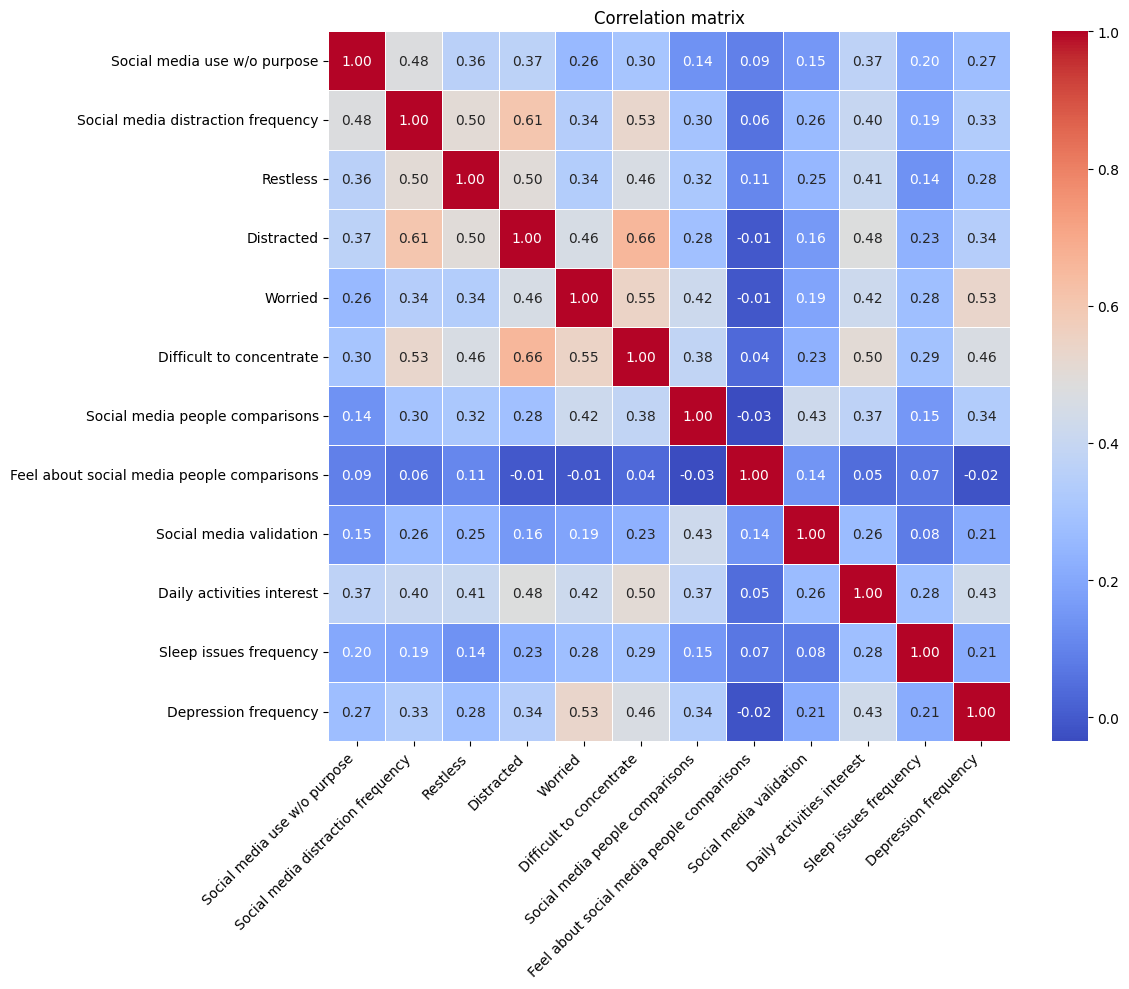

In [ ]:
#creating correlation matrix for key features
correlation_features = ['Social media use w/o purpose', 'Social media distraction frequency',
       'Restless', 'Distracted', 'Worried', 'Difficult to concentrate',
       'Social media people comparisons',
       'Feel about social media people comparisons', 'Social media validation',
       'Daily activities interest', 'Sleep issues frequency', 'Depression frequency']

correlation_matrix = df[correlation_features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot = True, cmap= 'coolwarm', fmt = '.2f', linewidths=0.5)
plt.title('Correlation matrix')
plt.xticks(rotation = 45, ha = 'right')
plt.tight_layout()
plt.show()

In [ ]:
#checking variance inflation factor to confirm multicollinearity

#selecting features from log-regression model
X_selected = df[correlation_features].drop(columns = ['Depression frequency'])

#adding constant column for intercept
X_features_const = add_constant(X_selected)

#creating dataframe to hold VIF values
vif_df = pd.DataFrame()
vif_df['Feature'] = X_features_const.columns
vif_df['VIF'] = [variance_inflation_factor(X_features_const.values, i)
  for i in range(X_features_const.shape[1])]

#sorting and display
vif_df.sort_values(by = 'VIF', ascending = False)

,Feature,VIF
0,const,24.364811
4,Distracted,2.287942
6,Difficult to concentrate,2.273457
2,Social media distraction frequency,1.993388
10,Daily activities interest,1.634636
5,Worried,1.633762
3,Restless,1.592692
7,Social media people comparisons,1.535370
1,Social media use w/o purpose,1.414075
9,Social media validation,1.310395


In [ ]:
#what just happened:

#quantifying how much the variance of a regression coefficient is inflated due to multicollinearity('mc'). this occurs when your predictors are correlated with each other .
# anything above 10 is a red flag
# the conlcuision is that even though the distraction column showed , the VIF was only 2.29 . Thats not very high. not high enough to be a problem.
# This negative coef is prob not due to collinearity. instead reflects an inverse relationship with other variables in the logreg model

# so, we dont know.

In [ ]:
#@title building a model for sleep issues frequency

In [ ]:
df['Sleep issues frequency'].value_counts()

,count
Sleep issues frequency,
0,229
1,217


In [ ]:
y_train2.value_counts()

,count
Sleep issues frequency,
0,178
1,178


In [ ]:
#splitting the data
X2 = df.drop(columns = ['Sleep issues frequency'])
y2 = df['Sleep issues frequency']

X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y2, test_size = 0.2, random_state = 42, stratify = y)

In [ ]:
#using logreg model first
logreg_sleep_model = LogisticRegression(max_iter = 1000, random_state = 42)

logreg_sleep_model.fit(X_train2, y_train2)

y_pred2 = logreg_sleep_model.predict(X_test2)

# Evaluate
print("Accuracy:", accuracy_score(y_test2, y_pred2))
print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred2))
print("Classification Report:\n", classification_report(y_test2, y_pred2))

Accuracy: 0.7111111111111111
Confusion Matrix:
 [[38 13]
 [13 26]]
Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.75      0.75        51
           1       0.67      0.67      0.67        39

    accuracy                           0.71        90
   macro avg       0.71      0.71      0.71        90
weighted avg       0.71      0.71      0.71        90



In [ ]:
#new model: K-Nearest Neighbors (KNN)

# neighbors = [1, 5, 6, 11, 20, 35, 52]
# for i in range(len(neighbors)):

#   n= neighbors[i]

  #init
knn_sleep = KNeighborsClassifier(n_neighbors=5)

  #train
knn_sleep.fit(X_train2, y_train2)

  #predict
y_pred2 = knn_sleep.predict(X_test2)

  #eval
print("Accuracy:", accuracy_score(y_test2, y_pred2))
print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred2))
print("Classification Report:\n", classification_report(y_test2, y_pred2))

Accuracy: 0.6111111111111112
Confusion Matrix:
 [[30 21]
 [14 25]]
Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.59      0.63        51
           1       0.54      0.64      0.59        39

    accuracy                           0.61        90
   macro avg       0.61      0.61      0.61        90
weighted avg       0.62      0.61      0.61        90



In [ ]:
#new model: Random Forest

#init model
rf_sleep_model = RandomForestClassifier(random_state = 42, n_estimators = 100, max_depth = 5)

#train model
rf_sleep_model.fit(X_train2, y_train2)

#testing model
y_pred2 = rf_sleep_model.predict(X_test2)

#eval
print("Accuracy:", accuracy_score(y_test2, y_pred2))
print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred2))
print("Classification Report:\n", classification_report(y_test2, y_pred2))

Accuracy: 0.5444444444444444
Confusion Matrix:
 [[29 22]
 [19 20]]
Classification Report:
               precision    recall  f1-score   support

           0       0.60      0.57      0.59        51
           1       0.48      0.51      0.49        39

    accuracy                           0.54        90
   macro avg       0.54      0.54      0.54        90
weighted avg       0.55      0.54      0.55        90



In [ ]:
#new model: Gradient Boosting

#init model
grad_boost_sleep_model = GradientBoostingClassifier(random_state = 42)

#train model
grad_boost_sleep_model.fit(X_train2, y_train2)

#predictions
y_pred2 = grad_boost_sleep_model.predict(X_test2)

#eval
print("Accuracy:", accuracy_score(y_test2, y_pred2))
print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred2))
print("Classification Report:\n", classification_report(y_test2, y_pred2))

Accuracy: 0.5111111111111111
Confusion Matrix:
 [[30 21]
 [23 16]]
Classification Report:
               precision    recall  f1-score   support

           0       0.57      0.59      0.58        51
           1       0.43      0.41      0.42        39

    accuracy                           0.51        90
   macro avg       0.50      0.50      0.50        90
weighted avg       0.51      0.51      0.51        90



In [ ]:
#new model: Decision Trees

#init model
tree_sleep_model = DecisionTreeClassifier(random_state = 42, max_depth = 5)

#train model
tree_sleep_model.fit(X_train2, y_train2)

#testing model
y_pred2 = tree_sleep_model.predict(X_test2)

#eval
print("Accuracy:", accuracy_score(y_test2, y_pred2))
print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred2))
print("Classification Report:\n", classification_report(y_test2, y_pred2))

Accuracy: 0.4
Confusion Matrix:
 [[21 30]
 [24 15]]
Classification Report:
               precision    recall  f1-score   support

           0       0.47      0.41      0.44        51
           1       0.33      0.38      0.36        39

    accuracy                           0.40        90
   macro avg       0.40      0.40      0.40        90
weighted avg       0.41      0.40      0.40        90



In [ ]:
#@title trying out NEURAL NETWORKS

# Scale features (very important for neural networks)
scaler = StandardScaler()
X_train_scaled2 = scaler.fit_transform(X_train2)
X_test_scaled2 = scaler.transform(X_test2)

# Build model
nn_sleep = Sequential()
nn_sleep.add(Dense(64, activation='relu', input_shape=(X_train_scaled2.shape[1],)))
nn_sleep.add(Dense(32, activation='relu'))
nn_sleep.add(Dense(1, activation='sigmoid'))  # Binary classification

# Compile
nn_sleep.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Train
history = nn_sleep.fit(X_train_scaled2, y_train2, epochs=30, batch_size=16, validation_split=0.2, verbose=1)

# Evaluate
loss, accuracy = nn_sleep.evaluate(X_test_scaled2, y_test2)
print("Test Accuracy:", accuracy)

y_pred_prob2 = nn_sleep.predict(X_test_scaled2)
y_pred2 = (y_pred_prob2 > 0.5).astype("int32")

print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred2))
print("Classification Report:\n", classification_report(y_test2, y_pred2))


Epoch 1/30


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.4882 - loss: 0.7543 - val_accuracy: 0.4583 - val_loss: 0.7564
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5540 - loss: 0.6651 - val_accuracy: 0.5417 - val_loss: 0.7232
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6143 - loss: 0.6406 - val_accuracy: 0.5139 - val_loss: 0.7283
Epoch 4/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6265 - loss: 0.5865 - val_accuracy: 0.5972 - val_loss: 0.7191
Epoch 5/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.6911 - loss: 0.5695 - val_accuracy: 0.5972 - val_loss: 0.7247
Epoch 6/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7209 - loss: 0.5324 - val_accuracy: 0.5694 - val_loss: 0.7318
Epoch 7/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6566 - loss: 0.5583 - val_accuracy: 0.5556 - val_loss: 0.7365
Epoch 8/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.7387 - loss: 0.4948 - val_accuracy: 0.5556 - val_loss: 0.

In [ ]:
#trying out CNNs

# 1. Scale your features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train2)
X_test_scaled = scaler.transform(X_test2)

# 2. Reshape for Conv1D: (samples, time steps, features)
X_train_cnn = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_test_cnn = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

# 3. Build the CNN model
cnn_sleep = Sequential()
cnn_sleep.add(Conv1D(filters=32, kernel_size=3, activation='relu', input_shape=(X_train_cnn.shape[1], 1)))
cnn_sleep.add(MaxPooling1D(pool_size=2))
cnn_sleep.add(Dropout(0.3))
cnn_sleep.add(Flatten())
cnn_sleep.add(Dense(64, activation='relu'))
cnn_sleep.add(Dropout(0.3))
cnn_sleep.add(Dense(1, activation='sigmoid'))  # Binary classification

# 4. Compile
optimizer = Adam(learning_rate=0.0005)
cnn_sleep.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# 5. Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# 6. Train
history = cnn_sleep.fit(
    X_train_cnn, y_train2,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# 7. Evaluate
loss, accuracy = cnn_sleep.evaluate(X_test_cnn, y_test2)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# 8. Predict & evaluate
y_pred_prob = cnn_sleep.predict(X_test_cnn)
y_pred2 = (y_pred_prob > 0.5).astype("int32")

print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred2))
print("Classification Report:\n", classification_report(y_test2, y_pred2))

Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.4535 - loss: 0.7241 - val_accuracy: 0.6111 - val_loss: 0.6607
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6278 - loss: 0.6645 - val_accuracy: 0.5833 - val_loss: 0.6585
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6297 - loss: 0.6518 - val_accuracy: 0.5694 - val_loss: 0.6562
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6103 - loss: 0.6507 - val_accuracy: 0.5694 - val_loss: 0.6558
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6606 - loss: 0.6497 - val_accuracy: 0.5694 - val_loss: 0.6602
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6277 - loss: 0.6346 - val_accuracy: 0.5694 - val_loss: 0.6646
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6529 - loss: 0.5929 - val_accuracy: 0.5556 - val_loss: 0.6741
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6573 - loss: 0.6143 - val_accuracy: 0.5833 - val_l

1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
Confusion Matrix:
 [[29 22]
 [13 26]]
Classification Report:
               precision    recall  f1-score   support

           0       0.69      0.57      0.62        51
           1       0.54      0.67      0.60        39

    accuracy                           0.61        90
   macro avg       0.62      0.62      0.61        90
weighted avg       0.63      0.61      0.61        90



In [ ]:
#@title fine tuning everything

In [ ]:
#logreg tuned

# Scale the features
scaler_sleep = StandardScaler()
X_train_sleep_scaled = scaler_sleep.fit_transform(X_train2)
X_test_sleep_scaled = scaler_sleep.transform(X_test2)

# Define parameter grid for tuning
param_grid_sleep = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear'],  # supports both l1 and l2 penalties
    'max_iter': [1000]
}

# Initialize and run GridSearchCV
logreg_sleep = LogisticRegression(random_state=42)
grid_sleep = GridSearchCV(logreg_sleep, param_grid_sleep, cv=5, scoring='f1', n_jobs=-1)
grid_sleep.fit(X_train_sleep_scaled, y_train2)

# Use the best model found
best_logreg_sleep = grid_sleep.best_estimator_
y_pred_sleep = best_logreg_sleep.predict(X_test_sleep_scaled)

# Evaluation
print("Tuned Logistic Regression - Sleep Prediction")
print("Best Parameters:", grid_sleep.best_params_)
print("Accuracy:", accuracy_score(y_test2, y_pred_sleep))
print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred_sleep))
print("Classification Report:\n", classification_report(y_test2, y_pred_sleep))

Tuned Logistic Regression - Sleep Prediction
Best Parameters: {'C': 0.01, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'liblinear'}
Accuracy: 0.6333333333333333
Confusion Matrix:
 [[32 19]
 [14 25]]
Classification Report:
               precision    recall  f1-score   support

           0       0.70      0.63      0.66        51
           1       0.57      0.64      0.60        39

    accuracy                           0.63        90
   macro avg       0.63      0.63      0.63        90
weighted avg       0.64      0.63      0.63        90



In [ ]:
#knn tuned

# Scale the features
scaler_sleep = StandardScaler()
X_train_sleep_scaled = scaler_sleep.fit_transform(X_train2)
X_test_sleep_scaled = scaler_sleep.transform(X_test2)

# Define parameter grid for tuning
param_grid_knn_sleep = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# Initialize and run GridSearchCV
knn_sleep = KNeighborsClassifier()
grid_knn_sleep = GridSearchCV(knn_sleep, param_grid_knn_sleep, cv=5, scoring='f1', n_jobs=-1)
grid_knn_sleep.fit(X_train_sleep_scaled, y_train2)

# Use the best model found
best_knn_sleep = grid_knn_sleep.best_estimator_
y_pred_knn_sleep = best_knn_sleep.predict(X_test_sleep_scaled)

# Evaluation
print("Tuned KNN - Sleep Prediction")
print("Best Parameters:", grid_knn_sleep.best_params_)
print("Accuracy:", accuracy_score(y_test2, y_pred_knn_sleep))
print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred_knn_sleep))
print("Classification Report:\n", classification_report(y_test2, y_pred_knn_sleep))

Tuned KNN - Sleep Prediction
Best Parameters: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'uniform'}
Accuracy: 0.5333333333333333
Confusion Matrix:
 [[29 22]
 [20 19]]
Classification Report:
               precision    recall  f1-score   support

           0       0.59      0.57      0.58        51
           1       0.46      0.49      0.47        39

    accuracy                           0.53        90
   macro avg       0.53      0.53      0.53        90
weighted avg       0.54      0.53      0.53        90



In [ ]:
#random forest tuned

# Scale the features
scaler_sleep = StandardScaler()
X_train_sleep_scaled = scaler_sleep.fit_transform(X_train2)
X_test_sleep_scaled = scaler_sleep.transform(X_test2)

# Define parameter grid
param_grid_rf_sleep = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7, None],
    'max_features': ['sqrt', 'log2'],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

# Grid search
rf_sleep_model = RandomForestClassifier(random_state=42)
grid_rf_sleep = GridSearchCV(rf_sleep_model, param_grid_rf_sleep, cv=5, scoring='f1', n_jobs=-1)
grid_rf_sleep.fit(X_train_sleep_scaled, y_train2)

# Predict
best_rf_sleep = grid_rf_sleep.best_estimator_
y_pred_rf_sleep = best_rf_sleep.predict(X_test_sleep_scaled)

# Eval
print("Tuned Random Forest - Sleep Prediction")
print("Best Parameters:", grid_rf_sleep.best_params_)
print("Accuracy:", accuracy_score(y_test2, y_pred_rf_sleep))
print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred_rf_sleep))
print("Classification Report:\n", classification_report(y_test2, y_pred_rf_sleep))


Tuned Random Forest - Sleep Prediction
Best Parameters: {'max_depth': 3, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Accuracy: 0.5888888888888889
Confusion Matrix:
 [[33 18]
 [19 20]]
Classification Report:
               precision    recall  f1-score   support

           0       0.63      0.65      0.64        51
           1       0.53      0.51      0.52        39

    accuracy                           0.59        90
   macro avg       0.58      0.58      0.58        90
weighted avg       0.59      0.59      0.59        90



In [ ]:
# gradient boosting tuned

# Define parameter grid
param_grid_gb_sleep = {
    'n_estimators': [100, 150],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0]
}

# Grid search
grad_boost_sleep_model = GradientBoostingClassifier(random_state=42)
grid_gb_sleep = GridSearchCV(grad_boost_sleep_model, param_grid_gb_sleep, cv=5, scoring='f1', n_jobs=-1)
grid_gb_sleep.fit(X_train_sleep_scaled, y_train2)

# Predict
best_gb_sleep = grid_gb_sleep.best_estimator_
y_pred_gb_sleep = best_gb_sleep.predict(X_test_sleep_scaled)

# Eval
print("Tuned Gradient Boosting - Sleep Prediction")
print("Best Parameters:", grid_gb_sleep.best_params_)
print("Accuracy:", accuracy_score(y_test2, y_pred_gb_sleep))
print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred_gb_sleep))
print("Classification Report:\n", classification_report(y_test2, y_pred_gb_sleep))


Tuned Gradient Boosting - Sleep Prediction
Best Parameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 150, 'subsample': 0.8}
Accuracy: 0.6111111111111112
Confusion Matrix:
 [[38 13]
 [22 17]]
Classification Report:
               precision    recall  f1-score   support

           0       0.63      0.75      0.68        51
           1       0.57      0.44      0.49        39

    accuracy                           0.61        90
   macro avg       0.60      0.59      0.59        90
weighted avg       0.60      0.61      0.60        90



In [ ]:
# decision tree tuned

# Define parameter grid
param_grid_tree_sleep = {
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Grid search
tree_sleep_model = DecisionTreeClassifier(random_state=42)
grid_tree_sleep = GridSearchCV(tree_sleep_model, param_grid_tree_sleep, cv=5, scoring='f1', n_jobs=-1)
grid_tree_sleep.fit(X_train_sleep_scaled, y_train2)

# Predict
best_tree_sleep = grid_tree_sleep.best_estimator_
y_pred_tree_sleep = best_tree_sleep.predict(X_test_sleep_scaled)

# Eval
print("Tuned Decision Tree - Sleep Prediction")
print("Best Parameters:", grid_tree_sleep.best_params_)
print("Accuracy:", accuracy_score(y_test2, y_pred_tree_sleep))
print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred_tree_sleep))
print("Classification Report:\n", classification_report(y_test2, y_pred_tree_sleep))


Tuned Decision Tree - Sleep Prediction
Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Accuracy: 0.5111111111111111
Confusion Matrix:
 [[32 19]
 [25 14]]
Classification Report:
               precision    recall  f1-score   support

           0       0.56      0.63      0.59        51
           1       0.42      0.36      0.39        39

    accuracy                           0.51        90
   macro avg       0.49      0.49      0.49        90
weighted avg       0.50      0.51      0.50        90



In [ ]:
# nn tuned

# Scale features
scaler_sleep = StandardScaler()
X_train_sleep_scaled = scaler_sleep.fit_transform(X_train2)
X_test_sleep_scaled = scaler_sleep.transform(X_test2)

# Manual tuning setup
best_acc_nn_sleep = 0
best_params_nn_sleep = {}

for units1 in [64, 128]:
    for units2 in [32, 64]:
        for dropout in [0.2, 0.3]:
            for lr in [0.001, 0.0005]:
                for batch in [16, 32]:
                    # Build model
                    model = Sequential([
                        Dense(units1, activation='relu', input_shape=(X_train_sleep_scaled.shape[1],)),
                        Dropout(dropout),
                        Dense(units2, activation='relu'),
                        Dropout(dropout),
                        Dense(1, activation='sigmoid')
                    ])

                    # Compile
                    model.compile(optimizer=Adam(learning_rate=lr), loss='binary_crossentropy', metrics=['accuracy'])

                    # Train
                    history = model.fit(
                        X_train_sleep_scaled, y_train2,
                        epochs=30,
                        batch_size=batch,
                        validation_split=0.2,
                        verbose=0  # Silent
                    )

                    # Evaluate
                    acc = model.evaluate(X_test_sleep_scaled, y_test2, verbose=0)[1]

                    if acc > best_acc_nn_sleep:
                        best_acc_nn_sleep = acc
                        best_params_nn_sleep = {
                            'units1': units1,
                            'units2': units2,
                            'dropout': dropout,
                            'lr': lr,
                            'batch': batch,
                            'model': model
                        }

# Final evaluation
print("Best Neural Net Accuracy:", best_acc_nn_sleep)
print("Best Parameters:", {k: v for k, v in best_params_nn_sleep.items() if k != 'model'})

# Predict
y_pred_prob_nn_sleep = best_params_nn_sleep['model'].predict(X_test_sleep_scaled)
y_pred_nn_sleep = (y_pred_prob_nn_sleep > 0.5).astype("int32")

print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred_nn_sleep))
print("Classification Report:\n", classification_report(y_test2, y_pred_nn_sleep))


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Best Neural Net Accuracy: 0.6777777671813965
Best Parameters: {'units1': 128, 'units2': 64, 'dropout': 0.3, 'lr': 0.001, 'batch': 16}
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Confusion Matrix:
 [[35 16]
 [13 26]]
Classification Report:
               precision    recall  f1-score   support

           0       0.73      0.69      0.71        51
           1       0.62      0.67      0.64        39

    accuracy                           0.68        90
   macro avg       0.67      0.68      0.67        90
weighted avg       0.68      0.68      0.68        90



In [ ]:
#cnn tuned

# Scale features
scaler_sleep = StandardScaler()
X_train_sleep_scaled = scaler_sleep.fit_transform(X_train2)
X_test_sleep_scaled = scaler_sleep.transform(X_test2)

# Reshape for Conv1D
X_train_cnn_sleep = X_train_sleep_scaled.reshape(X_train_sleep_scaled.shape[0], X_train_sleep_scaled.shape[1], 1)
X_test_cnn_sleep = X_test_sleep_scaled.reshape(X_test_sleep_scaled.shape[0], X_test_sleep_scaled.shape[1], 1)

# Manual tuning setup
best_acc_cnn_sleep = 0
best_params_cnn_sleep = {}

for filters in [32, 64]:
    for kernel in [3, 5]:
        for dropout in [0.2, 0.3]:
            for lr in [0.001, 0.0005]:
                # Build model
                model = Sequential([
                    Conv1D(filters=filters, kernel_size=kernel, activation='relu', input_shape=(X_train_cnn_sleep.shape[1], 1)),
                    MaxPooling1D(pool_size=2),
                    Dropout(dropout),
                    Flatten(),
                    Dense(64, activation='relu'),
                    Dropout(dropout),
                    Dense(1, activation='sigmoid')
                ])

                # Compile
                model.compile(optimizer=Adam(learning_rate=lr), loss='binary_crossentropy', metrics=['accuracy'])

                # Train with early stopping
                early_stop_sleep = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
                history = model.fit(
                    X_train_cnn_sleep, y_train2,
                    epochs=50,
                    batch_size=16,
                    validation_split=0.2,
                    callbacks=[early_stop_sleep],
                    verbose=0
                )

                acc = model.evaluate(X_test_cnn_sleep, y_test2, verbose=0)[1]

                if acc > best_acc_cnn_sleep:
                    best_acc_cnn_sleep = acc
                    best_params_cnn_sleep = {
                        'filters': filters,
                        'kernel': kernel,
                        'dropout': dropout,
                        'lr': lr,
                        'model': model
                    }

# Final evaluation
print("Best CNN Accuracy:", best_acc_cnn_sleep)
print("Best Parameters:", {k: v for k, v in best_params_cnn_sleep.items() if k != 'model'})

# Predict
y_pred_prob_cnn_sleep = best_params_cnn_sleep['model'].predict(X_test_cnn_sleep)
y_pred_cnn_sleep = (y_pred_prob_cnn_sleep > 0.5).astype("int32")

print("Confusion Matrix:\n", confusion_matrix(y_test2, y_pred_cnn_sleep))
print("Classification Report:\n", classification_report(y_test2, y_pred_cnn_sleep))


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Best CNN Accuracy: 0.6333333253860474
Best Parameters: {'filters': 32, 'kernel': 3, 'dropout': 0.2, 'lr': 0.0005}
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Confusion Matrix:
 [[30 21]
 [12 27]]
Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.59      0.65        51
           1       0.56      0.69      0.62        39

    accuracy                           0.63        90
   macro avg       0.64      0.64      0.63        90
weighted avg       0.65      0.63      0.63        90



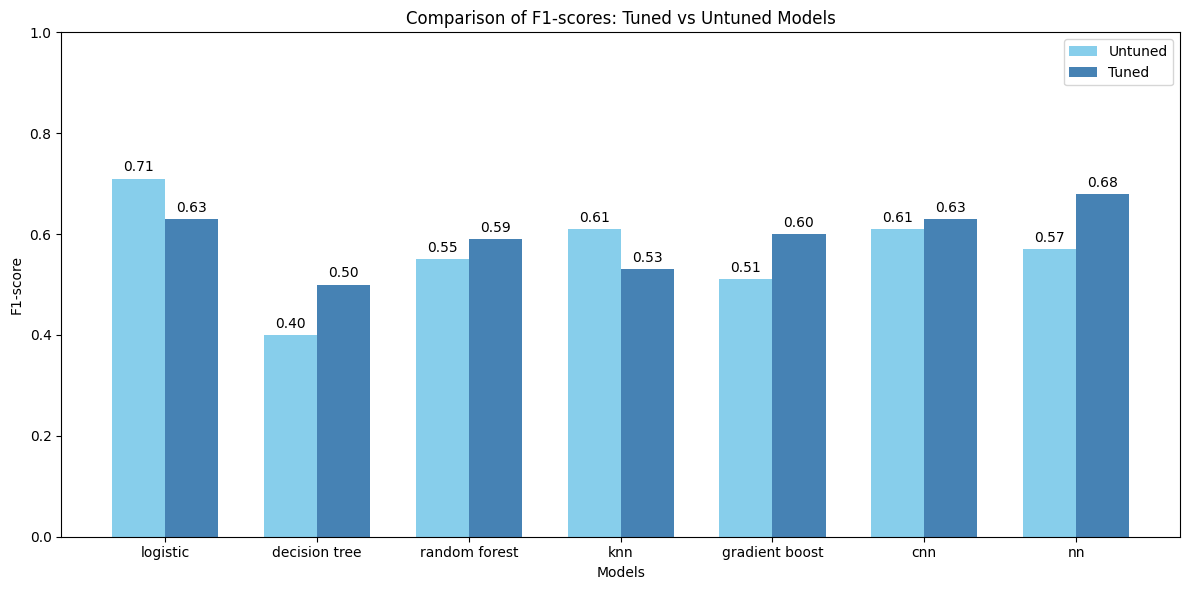

In [ ]:
#creating bar plot of all models that are tuned + UNtuned
models = ['logistic', 'decision tree', 'random forest', 'knn', 'gradient boost', 'cnn', 'nn']
f1_untuned = [0.71, 0.40, 0.55, 0.61, 0.51, 0.61, 0.57] #put in all numbers
f1_tuned = [0.63, 0.50, 0.59, 0.53, 0.60, 0.63, 0.68] #same here

x_label = np.arange(len(models))
width = 0.35
fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x_label - width/2, f1_untuned, width, label='Untuned', color='skyblue')
bars2 = ax.bar(x_label + width/2, f1_tuned, width, label='Tuned', color='steelblue')

# Add labels, title, and legend
ax.set_ylabel('F1-score')
ax.set_xlabel('Models')
ax.set_title('Comparison of F1-scores: Tuned vs Untuned Models')
ax.set_xticks(x_label)
ax.set_xticklabels(models)
ax.set_ylim(0, 1)
ax.legend()

# Annotate the bars with exact values
for bar in bars1 + bars2:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # vertical offset
                textcoords="offset points",
                ha='center', va='bottom')

plt.tight_layout()
plt.show()